#ANGGOTA GROUP
1. I Gede Parama Sathiyam Yuda Yana (2308561013)
2. I Ketut Tangkas Agus Sucita (2308561022)
3. Anak Agung Gede Angga Putra Wibawa (2308561099)
4. Komang Arjuntama Satria (2308561141)
5. Dewa Putu Adrian Paramarta (2308561134)

#1. Import

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from PIL import Image
import cv2

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import load_model
from google.colab import files

from sklearn.metrics import confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import classification_report


#2. Load Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

dataset_path = '/content/drive/MyDrive/dataset_pdl/klasifikasi_sampah'

Mounted at /content/drive


#3. Data Exploration

##3.1. Distribusi Kelas

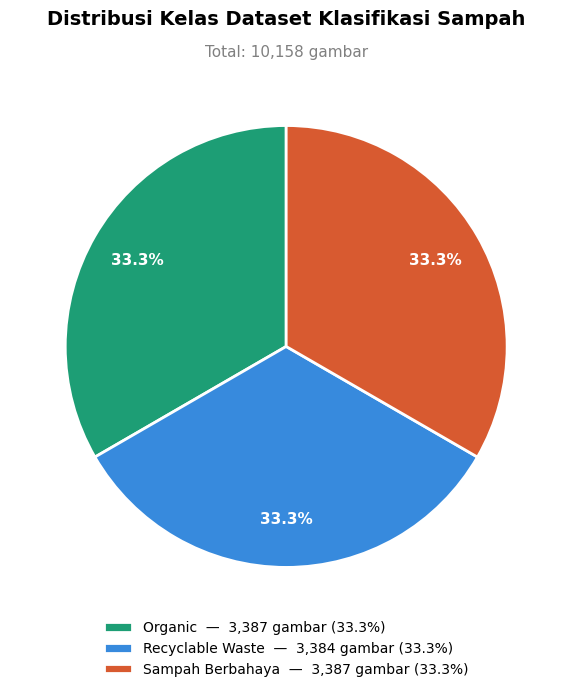

Total dataset : 10,158 gambar
  ORGANIC               : 3,387 gambar  (33.3%)
  RECYCLABLE WASTE      : 3,384 gambar  (33.3%)
  SAMPAH BERBAHAYA      : 3,387 gambar  (33.3%)


In [ ]:
dataset_path = '/content/drive/MyDrive/dataset_pdl/klasifikasi_sampah'
classes      = ['ORGANIC', 'RECYCLABLE WASTE', 'SAMPAH BERBAHAYA']
COLORS       = ['#1D9E75', '#378ADD', '#D85A30']
IMG_EXTS     = ('.jpg', '.jpeg', '.png', '.webp')

counts = []
for cls in classes:
    cls_dir = os.path.join(dataset_path, cls)
    files   = [f for f in os.listdir(cls_dir) if f.lower().endswith(IMG_EXTS)]
    counts.append(len(files))

total = sum(counts)

fig, ax = plt.subplots(figsize=(7, 7))
fig.suptitle('Distribusi Kelas Dataset Klasifikasi Sampah',
             fontsize=14, fontweight='bold')

wedges, texts, autotexts = ax.pie(
    counts,
    labels=None,
    colors=COLORS,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.78,
    wedgeprops=dict(linewidth=2, edgecolor='white')
)

for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
    at.set_color('white')

labels_legend = [
    f'{cls}  —  {count:,} gambar ({count/total*100:.1f}%)'
    for cls, count in zip(['Organic', 'Recyclable Waste', 'Sampah Berbahaya'], counts)
]
ax.legend(wedges, labels_legend,
          loc='lower center',
          bbox_to_anchor=(0.5, -0.12),
          fontsize=10,
          frameon=False)

ax.set_title(f'Total: {total:,} gambar', fontsize=11,
             color='gray', pad=10)

plt.tight_layout()
plt.savefig('distribusi_kelas.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Total dataset : {total:,} gambar")
for cls, count in zip(classes, counts):
    print(f"  {cls:<22}: {count:>5,} gambar  ({count/total*100:.1f}%)")

In [ ]:
print(f"Listing contents of: {dataset_path}")
!ls {dataset_path}

Listing contents of: /content/drive/MyDrive/dataset_pdl/klasifikasi_sampah
 ORGANIC  'RECYCLABLE WASTE'  'SAMPAH BERBAHAYA'


##3.2. Distribusi Ukuran Citra

Membaca dimensi gambar...
ORGANIC: 200 gambar
RECYCLABLE WASTE: 200 gambar
SAMPAH BERBAHAYA: 200 gambar


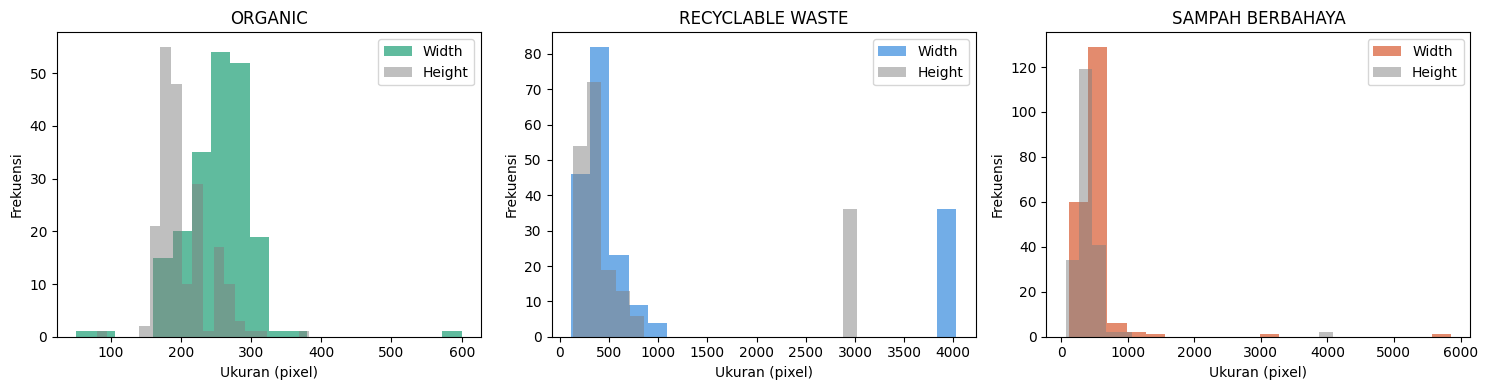

In [ ]:
MAX_SAMPLE = 200
size_data = {}

print("Membaca dimensi gambar...")

for cls in classes:
    widths, heights = [], []

    folder = os.path.join(dataset_path, cls)
    files = [f for f in os.listdir(folder) if f.lower().endswith(IMG_EXTS)][:MAX_SAMPLE]

    for file in files:
        try:
            with Image.open(os.path.join(folder, file)) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)
        except Exception:
            continue

    size_data[cls] = {
        "widths": widths,
        "heights": heights
    }

    print(f"{cls}: {len(widths)} gambar")

fig, axes = plt.subplots(1, len(classes), figsize=(15, 4))

for ax, cls, color in zip(axes, classes, COLORS):
    ax.hist(size_data[cls]["widths"],
            bins=20,
            color=color,
            alpha=0.7,
            label="Width")

    ax.hist(size_data[cls]["heights"],
            bins=20,
            color="gray",
            alpha=0.5,
            label="Height")

    ax.set_title(cls)
    ax.set_xlabel("Ukuran (pixel)")
    ax.set_ylabel("Frekuensi")
    ax.legend()

plt.tight_layout()
plt.show()

#4. Data Preprocessing

##4.1. Resize

In [ ]:
IMG_SIZE = 224

print("Validasi folder dataset...")
missing = []
for cls in classes:
    cls_dir = os.path.join(dataset_path, cls)
    if not os.path.isdir(cls_dir):
        missing.append(cls)
    else:
        n = len([f for f in os.listdir(cls_dir) if f.lower().endswith(IMG_EXTS)])
        print(f"  ✓ {cls}: {n} gambar ditemukan")

if missing:
    raise ValueError(f"Folder tidak ditemukan: {missing}. "
                     f"Periksa nama folder di dataset_path.")
else:
    print("Semua folder valid. Melanjutkan proses load...\n")

images = []
labels = []

MAX_PER_CLASS = 1000

print("Memuat dan me-resize gambar...")
for cls in classes:
    cls_dir = os.path.join(dataset_path, cls)
    files = [
        f for f in os.listdir(cls_dir)
        if f.lower().endswith(IMG_EXTS)
    ][:MAX_PER_CLASS]

    for file in files:
        img_path = os.path.join(cls_dir, file)
        try:
            img = cv2.imread(img_path)
            if img is None:
                continue

            if len(img.shape) == 2:
                img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
            elif img.shape[2] == 4:
                img = cv2.cvtColor(img, cv2.COLOR_BGRA2RGB)
            else:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

            images.append(img)
            labels.append(cls)

        except Exception:
            continue

images = np.array(images)

print(f"\nTotal gambar berhasil dibaca : {len(images):,}")
print(f"Shape images                 : {images.shape}")
print(f"\nDistribusi kelas yang dibaca:")
for cls in classes:
    count = labels.count(cls)
    print(f"  {cls:<25}: {count:,} gambar")

print(f"Total gambar berhasil dibaca : {len(images):,}")
print(f"Shape images : {images.shape}")

Validasi folder dataset...
  ✓ ORGANIC: 3387 gambar ditemukan
  ✓ RECYCLABLE WASTE: 3384 gambar ditemukan
  ✓ SAMPAH BERBAHAYA: 3387 gambar ditemukan
Semua folder valid. Melanjutkan proses load...

Memuat dan me-resize gambar...

Total gambar berhasil dibaca : 3,000
Shape images                 : (3000, 224, 224, 3)

Distribusi kelas yang dibaca:
  ORGANIC                  : 1,000 gambar
  RECYCLABLE WASTE         : 1,000 gambar
  SAMPAH BERBAHAYA         : 1,000 gambar
Total gambar berhasil dibaca : 3,000
Shape images : (3000, 224, 224, 3)


## 4.2. Verifikasi Hasil Resize

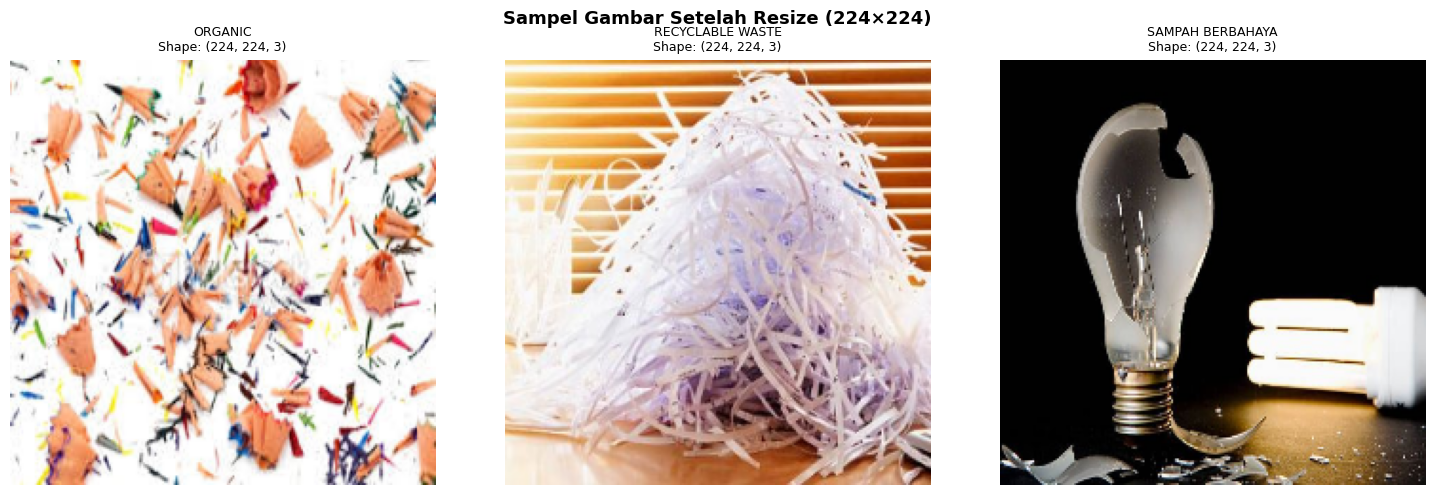

Shape array images : (3000, 224, 224, 3)
Tipe data          : uint8
Nilai piksel min   : 0
Nilai piksel max   : 255


In [ ]:
fig, axes = plt.subplots(1, len(classes), figsize=(5 * len(classes), 5))
fig.suptitle(f'Sampel Gambar Setelah Resize ({IMG_SIZE}×{IMG_SIZE})',
             fontsize=13, fontweight='bold')

for i, cls in enumerate(le_classes_preview := classes):
    idx = next(j for j, lbl in enumerate(labels) if lbl == cls)
    axes[i].imshow(images[idx])
    axes[i].set_title(f'{cls}\nShape: {images[idx].shape}', fontsize=9)
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('sampel_resize.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Shape array images : {images.shape}")
print(f"Tipe data          : {images.dtype}")
print(f"Nilai piksel min   : {images.min()}")
print(f"Nilai piksel max   : {images.max()}")

##4.3. Normalisasi

In [ ]:
images_norm = images.astype("float32") / 255.0

print("Normalisasi selesai")

print(
    f"Rentang nilai piksel : "
    f"{images_norm.min():.4f} "
    f"sampai "
    f"{images_norm.max():.4f}"
)

print(f"Shape images_norm : {images_norm.shape}")

Normalisasi selesai
Rentang nilai piksel : 0.0000 sampai 1.0000
Shape images_norm : (3000, 224, 224, 3)


##4.4. Label Encoding

In [ ]:
le = LabelEncoder()

labels_int = le.fit_transform(labels)

labels_ohe = to_categorical(
    labels_int,
    num_classes=len(classes)
)

print("Label Encoding selesai")
print("\nMapping Kelas:")

for i, cls in enumerate(le.classes_):
    print(f"{i} -> {cls}")

print("\nShape labels_int :", labels_int.shape)
print("Shape labels_ohe :", labels_ohe.shape)

print("\nOutput siap digunakan:")
print("✓ images_norm")
print("✓ labels_int")
print("✓ labels_ohe")
print("✓ le")

Label Encoding selesai

Mapping Kelas:
0 -> ORGANIC
1 -> RECYCLABLE WASTE
2 -> SAMPAH BERBAHAYA

Shape labels_int : (3000,)
Shape labels_ohe : (3000, 3)

Output siap digunakan:
✓ images_norm
✓ labels_int
✓ labels_ohe
✓ le


##4.5. Split Dataset

Hasil Split Dataset
  Total gambar    : 3,000
  Training  (80%) : 2,400 gambar  → shape: (2400, 224, 224, 3)
  Validation(20%) : 600 gambar  → shape: (600, 224, 224, 3)

Distribusi kelas per subset:
  Kelas                    Training   Validation
  --------------------------------------------
  ORGANIC                       800          200
  RECYCLABLE WASTE              800          200
  SAMPAH BERBAHAYA              800          200


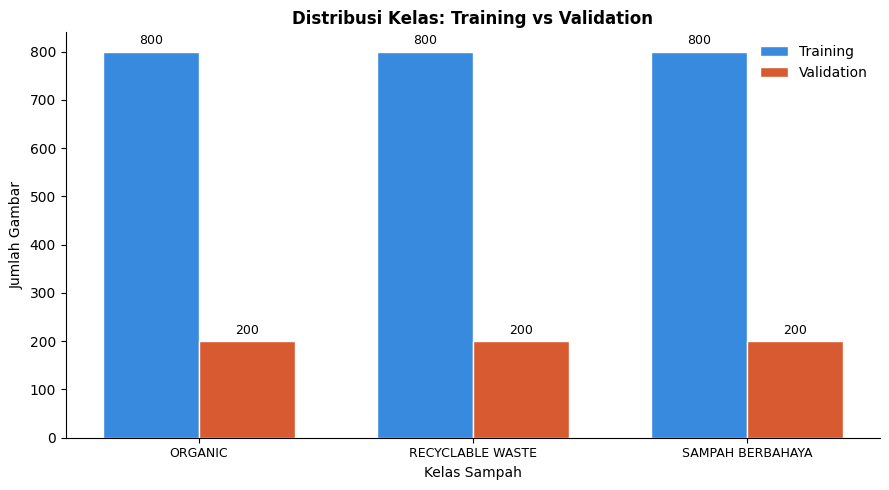

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    images_norm,
    labels_ohe,
    test_size=0.2,
    random_state=42,
    stratify=labels_int
)

total_split = len(X_train) + len(X_val)
print("Hasil Split Dataset")
print("="*45)
print(f"  Total gambar    : {total_split:,}")
print(f"  Training  (80%) : {len(X_train):,} gambar  → shape: {X_train.shape}")
print(f"  Validation(20%) : {len(X_val):,} gambar  → shape: {X_val.shape}")

y_train_int = np.argmax(y_train, axis=1)
y_val_int   = np.argmax(y_val,   axis=1)

print("\nDistribusi kelas per subset:")
print(f"  {'Kelas':<22} {'Training':>10} {'Validation':>12}")
print("  " + "-"*44)
for i, cls_name in enumerate(le.classes_):
    tr_cnt = np.sum(y_train_int == i)
    va_cnt = np.sum(y_val_int   == i)
    print(f"  {cls_name:<22} {tr_cnt:>10,} {va_cnt:>12,}")

x_pos    = np.arange(len(le.classes_))
tr_cnts  = [np.sum(y_train_int == i) for i in range(len(le.classes_))]
val_cnts = [np.sum(y_val_int   == i) for i in range(len(le.classes_))]
width    = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars1 = ax.bar(x_pos - width/2, tr_cnts,  width, label='Training',
               color='#378ADD', edgecolor='white')
bars2 = ax.bar(x_pos + width/2, val_cnts, width, label='Validation',
               color='#D85A30', edgecolor='white')

ax.bar_label(bars1, fmt='%d', padding=3, fontsize=9)
ax.bar_label(bars2, fmt='%d', padding=3, fontsize=9)

ax.set_xticks(x_pos)
ax.set_xticklabels(le.classes_, fontsize=9)
ax.set_title('Distribusi Kelas: Training vs Validation',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Kelas Sampah')
ax.set_ylabel('Jumlah Gambar')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('split_distribusi.png', dpi=150, bbox_inches='tight')
plt.show()

##4.6. Data Augmentation

Konfigurasi Data Augmentation
  Batch size           : 32
  Steps per epoch      : 75
  Validation steps     : 18
  Teknik augmentasi    : rotation, zoom, shift, flip
  Augmentasi validation: TIDAK (data asli)


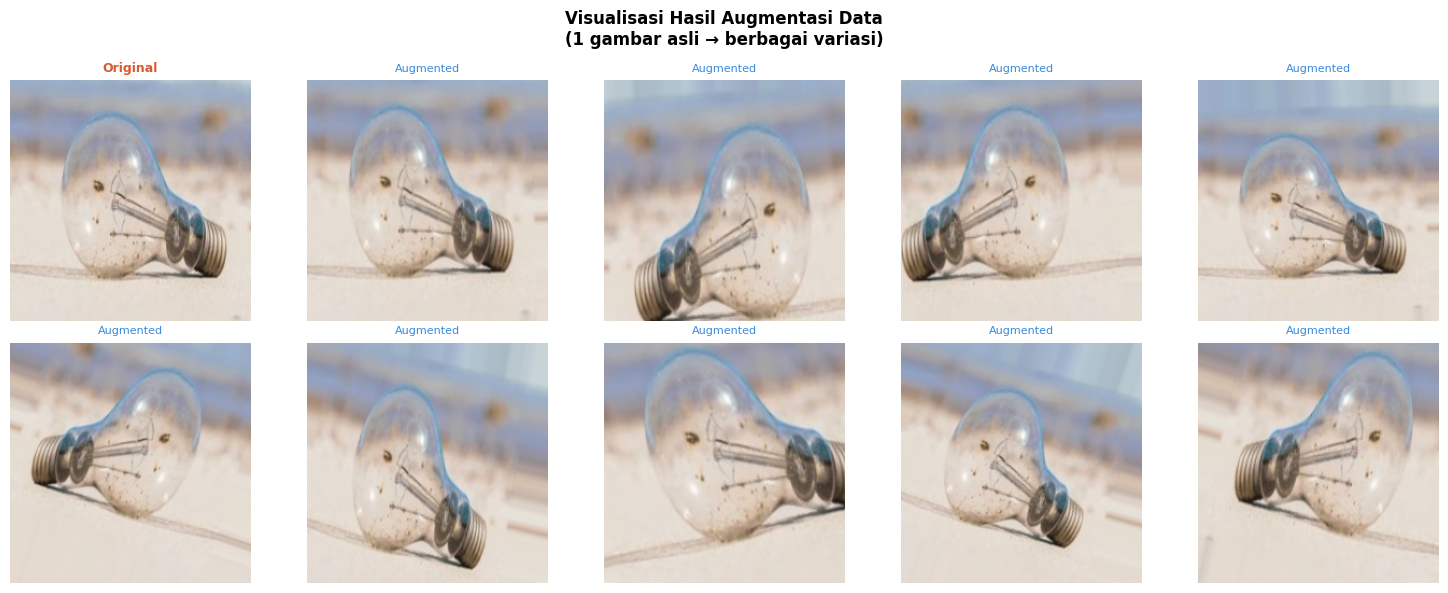


Generator siap digunakan untuk proses training.
  train_generator : 2,400 gambar  (dengan augmentasi)
  val_generator   : 600 gambar  (tanpa augmentasi)


In [ ]:
train_datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator()

BATCH_SIZE = 32

train_generator = train_datagen.flow(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow(
    X_val, y_val,
    batch_size=BATCH_SIZE,
    shuffle=False
)

steps_per_epoch  = len(X_train) // BATCH_SIZE
validation_steps = len(X_val)   // BATCH_SIZE

print("Konfigurasi Data Augmentation")
print("="*45)
print(f"  Batch size           : {BATCH_SIZE}")
print(f"  Steps per epoch      : {steps_per_epoch}")
print(f"  Validation steps     : {validation_steps}")
print(f"  Teknik augmentasi    : rotation, zoom, shift, flip")
print(f"  Augmentasi validation: TIDAK (data asli)")

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Visualisasi Hasil Augmentasi Data\n(1 gambar asli → berbagai variasi)',
             fontsize=12, fontweight='bold')

sample_img   = X_train[0:1]
sample_label = y_train[0:1]

axes[0, 0].imshow(sample_img[0])
axes[0, 0].set_title('Original', fontsize=9, fontweight='bold',
                      color='#D85A30')
axes[0, 0].axis('off')

aug_gen = train_datagen.flow(sample_img, sample_label,
                             batch_size=1, seed=0)
positions = [(0,1),(0,2),(0,3),(0,4),(1,0),(1,1),(1,2),(1,3),(1,4)]

for (row, col) in positions:
    aug_img, _ = next(aug_gen)
    axes[row, col].imshow(aug_img[0])
    axes[row, col].set_title('Augmented', fontsize=8, color='#378ADD')
    axes[row, col].axis('off')

plt.tight_layout()
plt.savefig('augmentasi_contoh.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nGenerator siap digunakan untuk proses training.")
print(f"  train_generator : {len(X_train):,} gambar  (dengan augmentasi)")
print(f"  val_generator   : {len(X_val):,} gambar  (tanpa augmentasi)")

#5. Model CNN

In [ ]:
IMG_SIZE = 224
NUM_CLASSES = 3

model_5block = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(512, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(NUM_CLASSES, activation='softmax')
])

model_5block.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 14, 14, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,421,699 (55.01 MB)

 Trainable params: 14,418,691 (55.00 MB)

 Non-trainable params: 3,008 (11.75 KB)

#6. Training Model

## 6.1. Konfigurasi Training



In [ ]:

model_5block.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model berhasil dikompilasi.")
print(f"  Optimizer : Adam (lr=1e-3 default)")
print(f"  Loss      : categorical_crossentropy")
print(f"  Metrics   : accuracy")

CHECKPOINT_PATH = 'best_model.keras'
EPOCHS          = 50

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=CHECKPOINT_PATH,
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

print(f"\nKonfigurasi Callback:")
print(f"  EarlyStopping       : patience=7, monitor=val_loss")
print(f"  ModelCheckpoint     : simpan bobot terbaik → {CHECKPOINT_PATH}")
print(f"  ReduceLROnPlateau   : factor=0.5, patience=3, min_lr=1e-6")
print(f"\nJumlah epoch maksimum : {EPOCHS}")

Model berhasil dikompilasi.
  Optimizer : Adam (lr=1e-3 default)
  Loss      : categorical_crossentropy
  Metrics   : accuracy

Konfigurasi Callback:
  EarlyStopping       : patience=7, monitor=val_loss
  ModelCheckpoint     : simpan bobot terbaik → best_model.keras
  ReduceLROnPlateau   : factor=0.5, patience=3, min_lr=1e-6

Jumlah epoch maksimum : 50


##6.2. Implementasi Training pada Dataset

In [ ]:
print("Memulai training model...")
print("=" * 55)

history = model_5block.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=val_generator,
    validation_steps=validation_steps,
    callbacks=callbacks,
    verbose=1
)

print("\nTraining selesai.")
print(f"  Epoch berjalan      : {len(history.history['loss'])}")
print(f"  Best val_accuracy   : {max(history.history['val_accuracy']):.4f}")
print(f"  Best val_loss       : {min(history.history['val_loss']):.4f}")

Memulai training model...
Epoch 1/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step - accuracy: 0.4707 - loss: 2.0587
Epoch 1: val_accuracy improved from None to 0.34896, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
75/75 ━━━━━━━━━━━━━━━━━━━━ 49s 450ms/step - accuracy: 0.4946 - loss: 1.5798 - val_accuracy: 0.3490 - val_loss: 1.5041 - learning_rate: 0.0010
Epoch 2/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - accuracy: 0.5356 - loss: 1.1993
Epoch 2: val_accuracy improved from 0.34896 to 0.35417, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
75/75 ━━━━━━━━━━━━━━━━━━━━ 31s 414ms/step - accuracy: 0.5496 - loss: 1.1178 - val_accuracy: 0.3542 - val_loss: 1.8592 - learning_rate: 0.0010
Epoch 3/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 395ms/step - accuracy: 0.5448 - loss: 1.1019
Epoch 3: val_accuracy did not improve from 0.35417
75/75 ━━━━━━━━━━━━━━━━━━━━ 30s 402ms/step - accuracy: 0.5529 - loss: 1.0635 - val_accuracy: 0.3403 - v

##6.3. Visualisasi Training

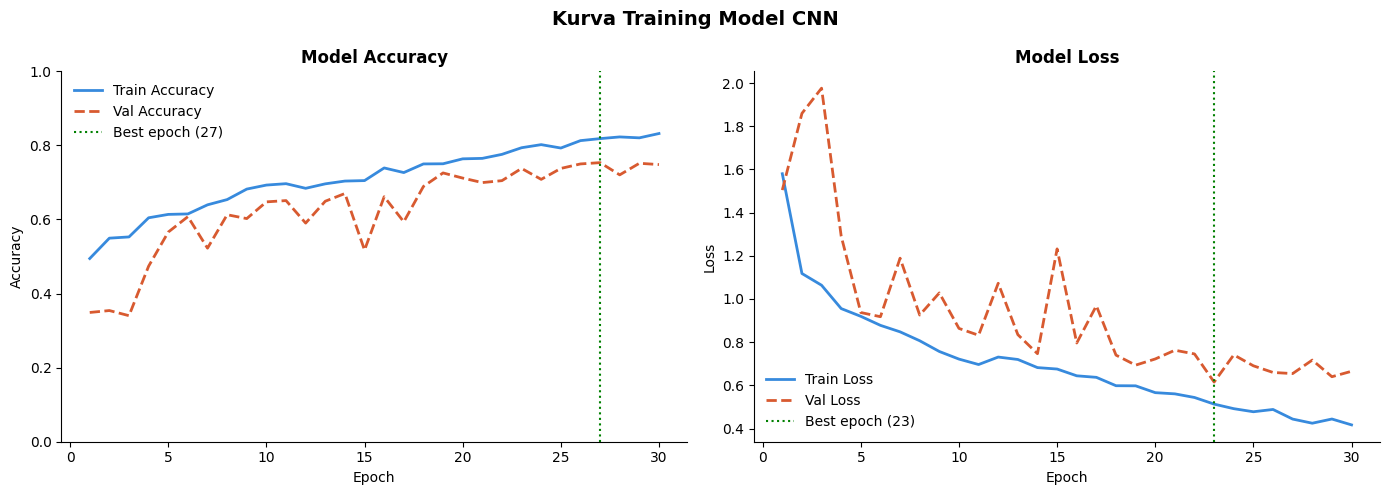


RINGKASAN HASIL TRAINING
  Total epoch berjalan    : 30
  Best val_accuracy       : 0.7535  (epoch 27)
  Best val_loss           : 0.6151  (epoch 23)
  Final train_accuracy    : 0.8321
  Final train_loss        : 0.4168

Model terbaik disimpan di: best_model.keras


In [ ]:
epochs_range = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Kurva Training Model CNN', fontsize=14, fontweight='bold')

axes[0].plot(epochs_range, history.history['accuracy'],
             color='#378ADD', linewidth=2, label='Train Accuracy')
axes[0].plot(epochs_range, history.history['val_accuracy'],
             color='#D85A30', linewidth=2, linestyle='--', label='Val Accuracy')
axes[0].set_title('Model Accuracy', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend(frameon=False)
axes[0].spines[['top', 'right']].set_visible(False)
axes[0].set_ylim([0, 1])

best_epoch = np.argmax(history.history['val_accuracy']) + 1
best_val_acc = max(history.history['val_accuracy'])
axes[0].axvline(x=best_epoch, color='green', linestyle=':', linewidth=1.5,
                label=f'Best epoch ({best_epoch})')
axes[0].legend(frameon=False)

axes[1].plot(epochs_range, history.history['loss'],
             color='#378ADD', linewidth=2, label='Train Loss')
axes[1].plot(epochs_range, history.history['val_loss'],
             color='#D85A30', linewidth=2, linestyle='--', label='Val Loss')
axes[1].set_title('Model Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend(frameon=False)
axes[1].spines[['top', 'right']].set_visible(False)

best_val_loss = min(history.history['val_loss'])
best_loss_epoch = np.argmin(history.history['val_loss']) + 1
axes[1].axvline(x=best_loss_epoch, color='green', linestyle=':', linewidth=1.5,
                label=f'Best epoch ({best_loss_epoch})')
axes[1].legend(frameon=False)

plt.tight_layout()
plt.savefig('kurva_training.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "=" * 50)
print("RINGKASAN HASIL TRAINING")
print("=" * 50)
print(f"  Total epoch berjalan    : {len(epochs_range)}")
print(f"  Best val_accuracy       : {best_val_acc:.4f}  (epoch {best_epoch})")
print(f"  Best val_loss           : {best_val_loss:.4f}  (epoch {best_loss_epoch})")
print(f"  Final train_accuracy    : {history.history['accuracy'][-1]:.4f}")
print(f"  Final train_loss        : {history.history['loss'][-1]:.4f}")
print(f"\nModel terbaik disimpan di: {CHECKPOINT_PATH}")

#7. Evaluasi

##7.1. Evaluasi pada Data Validasi


In [ ]:
val_loss, val_accuracy = model_5block.evaluate(
    X_val, y_val,
    verbose=1
)

print("\n" + "=" * 50)
print("HASIL EVALUASI PADA DATA VALIDASI")
print("=" * 50)
print(f"  Validation Loss     : {val_loss:.4f}")
print(f"  Validation Accuracy : {val_accuracy:.4f}  ({val_accuracy*100:.2f}%)")

final_train_acc  = history.history['accuracy'][-1]
final_train_loss = history.history['loss'][-1]
gap_acc  = final_train_acc - val_accuracy
gap_loss = val_loss - final_train_loss

print(f"\n  Training Accuracy   : {final_train_acc:.4f}")
print(f"  Training Loss       : {final_train_loss:.4f}")
print(f"\n  Gap Accuracy (train - val)  : {gap_acc:+.4f}")
print(f"  Gap Loss     (val - train)  : {gap_loss:+.4f}")

if gap_acc > 0.10:
    print("\n   Gap accuracy cukup besar → kemungkinan overfitting.")
elif gap_acc < 0.02:
    print("\n  Gap sangat kecil → model generalisasi dengan baik.")
else:
    print("\n   Gap moderat → masih dalam batas wajar.")

19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 123ms/step - accuracy: 0.7417 - loss: 0.6134

HASIL EVALUASI PADA DATA VALIDASI
  Validation Loss     : 0.6134
  Validation Accuracy : 0.7417  (74.17%)

  Training Accuracy   : 0.8321
  Training Loss       : 0.4168

  Gap Accuracy (train - val)  : +0.0904
  Gap Loss     (val - train)  : +0.1967

   Gap moderat → masih dalam batas wajar.


##7.2. Laporan Evaluasi

In [ ]:
y_pred_proba = model_5block.predict(X_val, verbose=1)
y_pred_int   = np.argmax(y_pred_proba, axis=1)
y_true_int   = np.argmax(y_val, axis=1)

class_names = le.classes_

print("=" * 65)
print("CLASSIFICATION REPORT")
print("=" * 65)
print(classification_report(
    y_true_int,
    y_pred_int,
    target_names=class_names,
    digits=4
))

19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step
CLASSIFICATION REPORT
                  precision    recall  f1-score   support

         ORGANIC     0.7767    0.8000    0.7882       200
RECYCLABLE WASTE     0.7073    0.7250    0.7160       200
SAMPAH BERBAHAYA     0.7407    0.7000    0.7198       200

        accuracy                         0.7417       600
       macro avg     0.7416    0.7417    0.7413       600
    weighted avg     0.7416    0.7417    0.7413       600



##7.3. Confusion Matrix

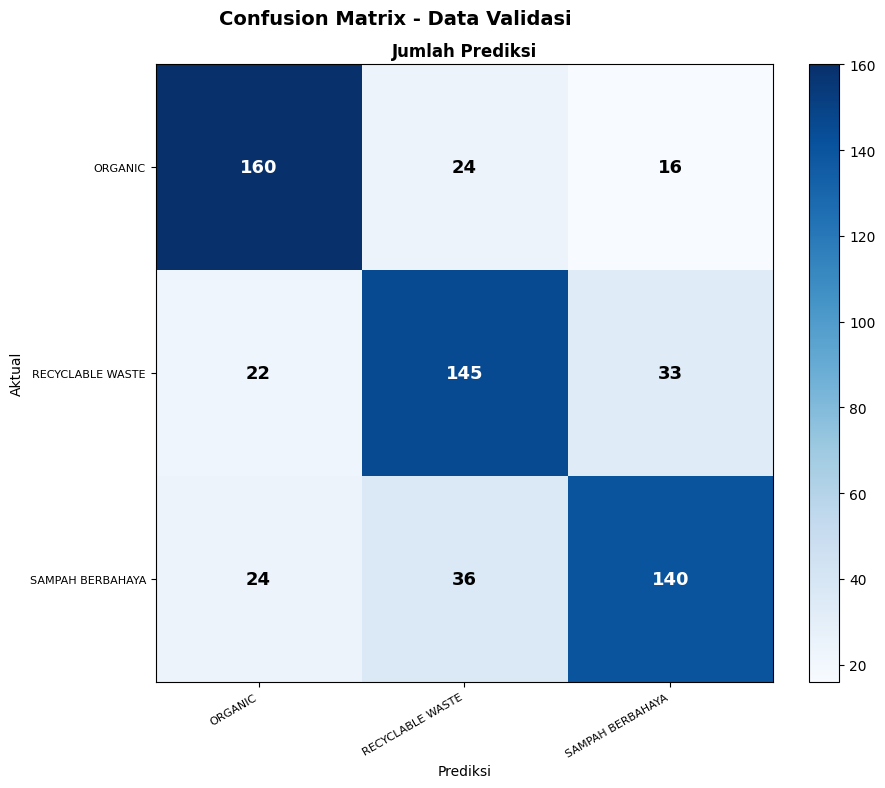


ANALISIS TP, TN, FP, FN PER KELAS (One-vs-Rest)
Kelas                         TP     TN     FP     FN
-------------------------------------------------------
  ORGANIC                    160    354     46     40
  RECYCLABLE WASTE           145    340     60     55
  SAMPAH BERBAHAYA           140    351     49     60
-------------------------------------------------------
  Total sampel validasi : 600

RINGKASAN KESALAHAN KLASIFIKASI
  ORGANIC                   -> salah prediksi sebagai RECYCLABLE WASTE          :   24 sampel
  ORGANIC                   -> salah prediksi sebagai SAMPAH BERBAHAYA          :   16 sampel
  RECYCLABLE WASTE          -> salah prediksi sebagai ORGANIC                   :   22 sampel
  RECYCLABLE WASTE          -> salah prediksi sebagai SAMPAH BERBAHAYA          :   33 sampel
  SAMPAH BERBAHAYA          -> salah prediksi sebagai ORGANIC                   :   24 sampel
  SAMPAH BERBAHAYA          -> salah prediksi sebagai RECYCLABLE WASTE          :   36 sam

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true_int, y_pred_int)

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
fig.suptitle('Confusion Matrix - Data Validasi', fontsize=14, fontweight='bold')

im1 = ax.imshow(cm, interpolation='nearest', cmap='Blues')
ax.set_title('Jumlah Prediksi', fontsize=12, fontweight='bold')
ax.set_xlabel('Prediksi', fontsize=10)
ax.set_ylabel('Aktual', fontsize=10)
ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, fontsize=8, rotation=30, ha='right')
ax.set_yticklabels(class_names, fontsize=8)
plt.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i, f'{cm[i, j]}',
                ha='center', va='center',
                fontsize=13, fontweight='bold', color=color)

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "=" * 65)
print("ANALISIS TP, TN, FP, FN PER KELAS (One-vs-Rest)")
print("=" * 65)
print(f"{'Kelas':<25s} {'TP':>6} {'TN':>6} {'FP':>6} {'FN':>6}")
print("-" * 55)

for idx_cls in range(len(class_names)):
    tp = cm[idx_cls, idx_cls]
    fn = cm[idx_cls, :].sum() - tp
    fp = cm[:, idx_cls].sum() - tp
    tn = cm.sum() - tp - fn - fp

    print(f"  {class_names[idx_cls]:<23s} {tp:>6} {tn:>6} {fp:>6} {fn:>6}")

print("-" * 55)
print(f"  Total sampel validasi : {cm.sum()}")

print("\nRINGKASAN KESALAHAN KLASIFIKASI")
print("=" * 55)
total_errors = 0
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            print(f"  {class_names[i]:25s} -> salah prediksi sebagai "
                  f"{class_names[j]:25s} : {cm[i, j]:>4} sampel")
            total_errors += cm[i, j]
print(f"\n  Total kesalahan : {total_errors} dari {cm.sum()} sampel "
      f"({total_errors/cm.sum()*100:.2f}%)")

#8. Simpan Model

In [ ]:
model.save('best_model.keras')

print("Model berhasil disimpan sebagai best_model.keras")

from google.colab import files
files.download('best_model.keras')

Model berhasil disimpan sebagai best_model.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>